# unCLIP: contrastive encoder training
Run the cells in order. Select **Runtime → Change runtime type → GPU** first.
This notebook sets up the required baseline; full training starts only in the final training cell.
Use the accompanying `unclip-colab-code.zip`. Do not install your Mac's requirements-lock file here.


In [26]:
import sys, torch
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
assert torch.cuda.is_available(), "Select a GPU runtime before continuing"
print("GPU:", torch.cuda.get_device_name(0))


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
GPU: Tesla T4


## 1. Mount Google Drive
Authorize access yourself. Checkpoints and a backup of data indices go into MyDrive/unclip_project. Raw images remain in /content for faster access.

In [27]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
DRIVE = Path('/content/drive/MyDrive/unclip_project')
DRIVE.mkdir(parents=True, exist_ok=True)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Upload the code bundle
Choose `unclip-colab-code.zip` from your computer. This contains prepare_data.py and train_embedding.py.

In [28]:
from google.colab import files
from pathlib import Path
import io, zipfile, os, shutil

WORK = Path("/content/unclip_project")
WORK.mkdir(exist_ok=True)

uploaded = files.upload()
assert len(uploaded) == 1, "Upload only the code ZIP"

name, contents = next(iter(uploaded.items()))

with zipfile.ZipFile(io.BytesIO(contents)) as z:
    for filename in [
        "prepare_data.py",
        "train_embedding.py",
        "requirements.txt",
    ]:
        (WORK / filename).write_bytes(z.read(filename))

os.chdir(WORK)
print("Code extracted from:", name)
print("Working directory:", WORK)

Saving unclip-colab-code.zip to unclip-colab-code (4).zip
Code extracted from: unclip-colab-code (4).zip
Working directory: /content/unclip_project


## 3. Check dependencies
Keep Colab’s provided CUDA PyTorch. Install only the remaining packages if needed.

In [29]:
%pip -q install scikit-learn scipy matplotlib
import torchvision, sklearn, scipy, matplotlib, numpy as np
print('torchvision:', torchvision.__version__)
print('scipy:', scipy.__version__)
print('scikit-learn:', sklearn.__version__)


torchvision: 0.29.1+cu130
scipy: 1.16.3
scikit-learn: 1.6.1


## 4. Reuse your saved indices, or prepare them once
**If you already prepared data on your Mac:** compress `data/indices/seed_2026` into a ZIP, set UPLOAD_EXISTING_INDICES=True below, and upload it. Do not include raw images or environments.
If no preparation has completed anywhere, leave it False. The script will generate the splits/pairs and download the images.
On reconnect, the notebook restores the saved index folder from Drive automatically.


In [30]:
from pathlib import Path
from datetime import datetime

INDEX = WORK / "data/indices/seed_2026"
BACKUP = DRIVE / "indices/seed_2026"
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Preserve incomplete folders so Step 4 can retry.
for folder in [INDEX, BACKUP]:
    if folder.exists() and not (folder / "manifest.json").exists():
        preserved = folder.with_name(f"{folder.name}_incomplete_{stamp}")
        folder.rename(preserved)
        print("Preserved incomplete folder:", preserved)

In [31]:
UPLOAD_EXISTING_INDICES = True  # Set True if your Mac already has saved indices.
INDEX = WORK / 'data/indices/seed_2026'
BACKUP = DRIVE / 'indices/seed_2026'
if BACKUP.exists() and not INDEX.exists():
    shutil.copytree(BACKUP, INDEX)
if UPLOAD_EXISTING_INDICES and not INDEX.exists():
    upload = files.upload()
    assert len(upload) == 1, 'Upload one ZIP of your saved indices'
    with zipfile.ZipFile(io.BytesIO(next(iter(upload.values())))) as z:
        manifests = [n for n in z.namelist() if Path(n).name == 'manifest.json' and '__MACOSX' not in n]
        assert len(manifests) == 1, 'ZIP must contain exactly one seed folder'
        prefix = str(Path(manifests[0]).parent)
        prefix = '' if prefix == '.' else prefix + '/'
        INDEX.mkdir(parents=True)
        for entry in z.namelist():
            relative = entry[len(prefix):] if entry.startswith(prefix) else ''
            if relative and '/' not in relative and relative.endswith(('.npy', '.npz', '.json', '.png')):
                (INDEX / relative).write_bytes(z.read(entry))
if not INDEX.exists():
    import subprocess
    subprocess.run([sys.executable, 'prepare_data.py', '--seed', '2026'], check=True)
assert (INDEX / 'manifest.json').exists(), 'Data preparation is incomplete'
import json, hashlib
manifest = json.loads((INDEX / 'manifest.json').read_text())
assert manifest['seed'] == 2026
for filename, expected in manifest['sha256'].items():
    assert hashlib.sha256((INDEX / filename).read_bytes()).hexdigest() == expected, filename
if not BACKUP.exists():
    BACKUP.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(INDEX, BACKUP)
print('Indices verified and backed up:', BACKUP)
print('Pair counts:', manifest['pair_counts'])


Saving seed_2026.zip to seed_2026.zip
Indices verified and backed up: /content/drive/MyDrive/unclip_project/indices/seed_2026
Pair counts: {'train': 2398620, 'val': 266520, 'test': 720640}


## 5. Download raw images and inspect fixed examples
When reusing indices, downloads must use the original torchvision datasets. No additional split is created.

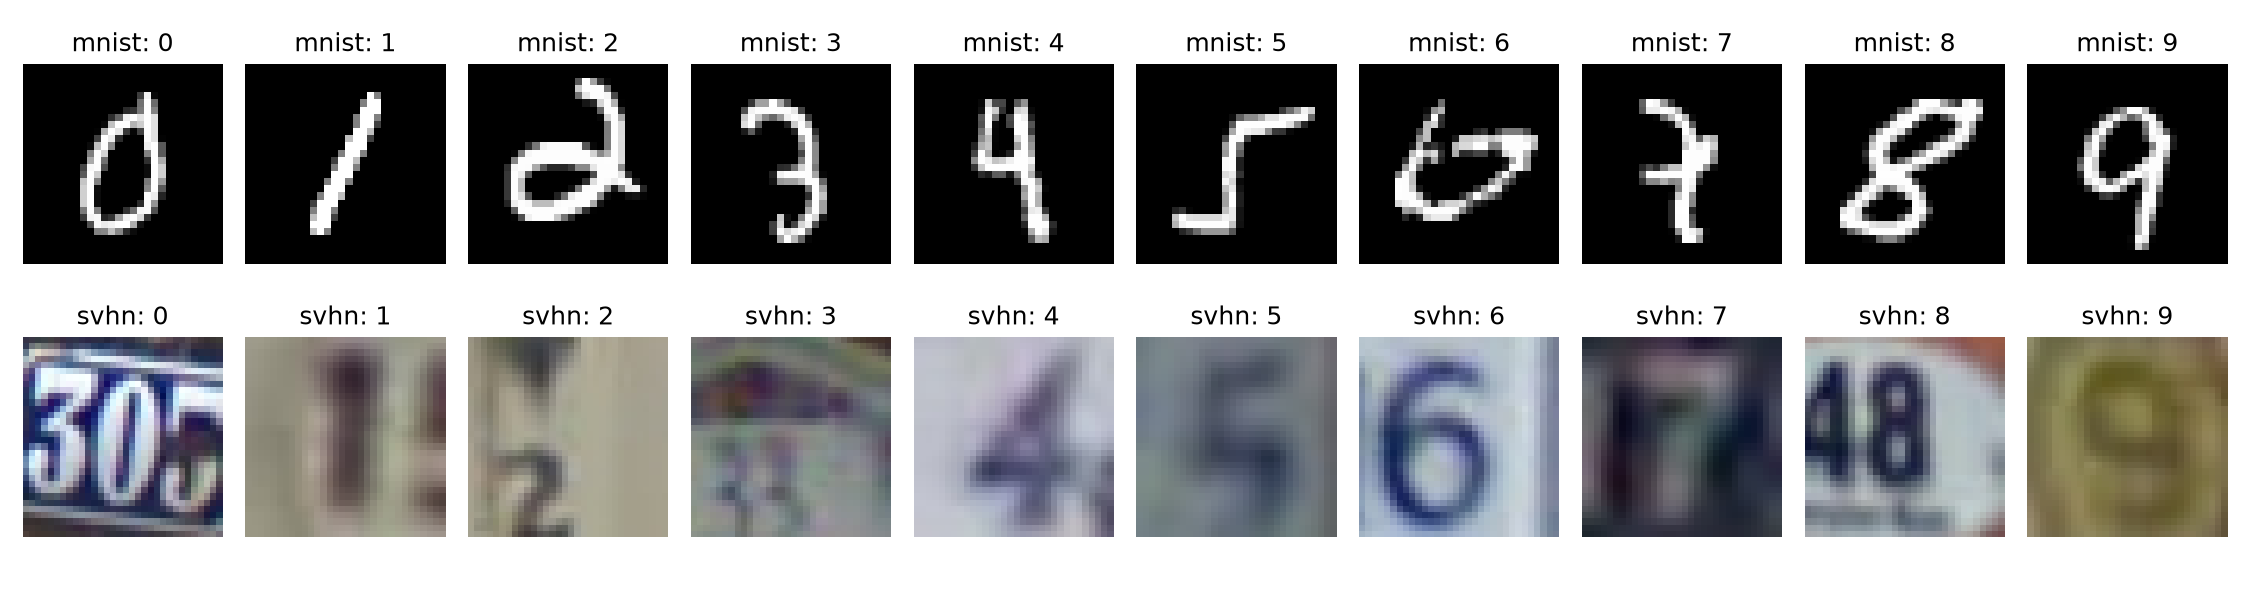

In [32]:
from torchvision.datasets import MNIST, SVHN
from IPython.display import Image, display
for train in [True, False]:
    MNIST('data/raw', train=train, download=True)
for split in ['train', 'test']:
    SVHN('data/raw/SVHN', split=split, download=True)
display(Image(filename=str(INDEX / 'dataset_preview.png')))


## 6. Smoke test: 10 updates
This checks the code on the assigned GPU. It saves to a separate folder and is NOT your reported baseline.
Training uses labels only indirectly through the saved pairs. The InfoNCE positives are the diagonal pairs, not all examples of the same digit.


In [33]:
import subprocess
subprocess.run([sys.executable, 'train_embedding.py', '--output', str(WORK / 'smoke_run'),
                '--steps', '10', '--save-every', '10', '--resume'], check=True)


CompletedProcess(args=['/usr/bin/python3', 'train_embedding.py', '--output', '/content/unclip_project/smoke_run', '--steps', '10', '--save-every', '10', '--resume'], returncode=0)

## 7. Train the official baseline: 30,000 updates
Run this when ready to start the full training. Adam 0.001, batch 256, normalized 64D embeddings, learnable temperature initially 0.07. No mixed precision is used, so each iteration is one optimizer update.
Checkpoints are saved every 500 updates to Google Drive. To resume after disconnection, rerun the setup cells and this same command. Keep the same data, configuration, package versions, and preferably GPU type; identical random states do not guarantee identical results on different hardware.
The saved checkpoint includes model, optimizer, batch permutation/position, loss history, and Python/NumPy/PyTorch/CUDA RNG states.


In [34]:
RUN = DRIVE / 'runs/embedding_seed_2026'
RUN.mkdir(parents=True, exist_ok=True)
with (RUN / 'requirements-gpu-lock.txt').open('w') as f:
    subprocess.run([sys.executable, '-m', 'pip', 'freeze'], stdout=f, check=True)
# Snapshot the exact scripts used for this run.
for name in ['train_embedding.py', 'prepare_data.py']:
    destination = RUN / name
    if destination.exists():
        assert destination.read_bytes() == (WORK / name).read_bytes(), 'Training code changed; use a new run folder'
    else:
        shutil.copy2(WORK / name, destination)
subprocess.run([sys.executable, '-u', 'train_embedding.py', '--output', str(RUN),
                '--steps', '30000', '--save-every', '500', '--resume'], check=True)


CompletedProcess(args=['/usr/bin/python3', '-u', 'train_embedding.py', '--output', '/content/drive/MyDrive/unclip_project/runs/embedding_seed_2026', '--steps', '30000', '--save-every', '500', '--resume'], returncode=0)

## 8. Inspect the result
`frozen_encoders.pt` appears only after 30,000 updates. Next, evaluate precision@10, prompt accuracy, and digit/style linear probes before training decoders. This notebook does not implement those evaluations yet. InfoNCE loss need not approach zero because batch examples can share a digit.

Completed updates: 30000
Final encoder artifact: True


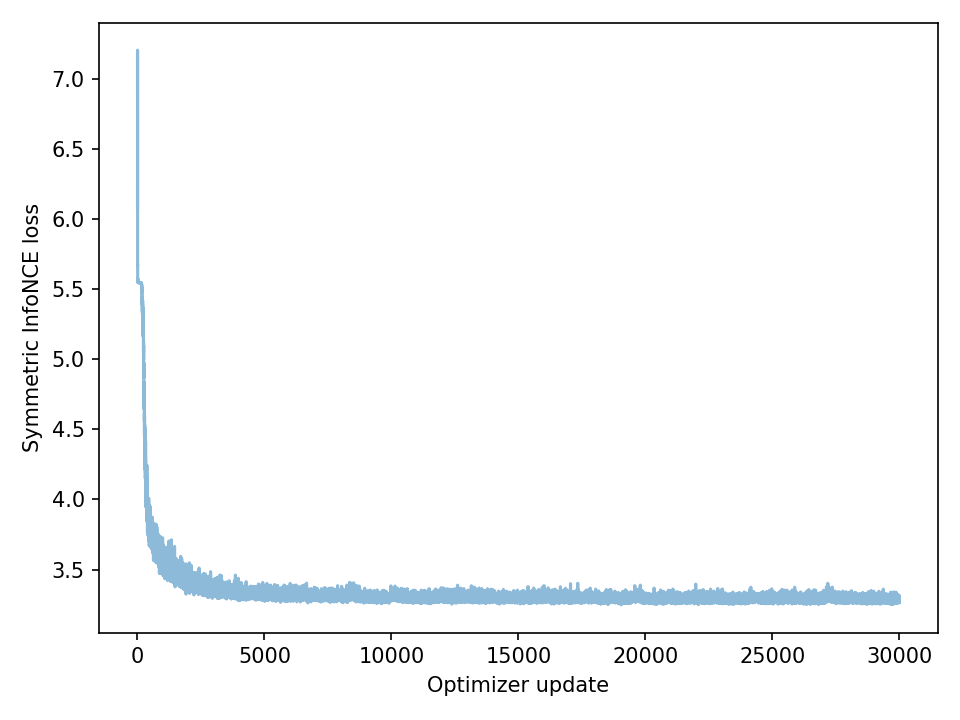

In [35]:
ck = torch.load(RUN / 'latest.pt', map_location='cpu', weights_only=False)
print('Completed updates:', ck['step'])
print('Final encoder artifact:', (RUN / 'frozen_encoders.pt').exists())
display(Image(filename=str(RUN / 'training_loss.png')))
